In [24]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report,confusion_matrix,ConfusionMatrixDisplay,recall_score,f1_score
from sklearn.metrics import roc_auc_score,roc_curve,precision_recall_curve,precision_score

In [25]:
df=pd.read_csv("C:/Users/space/Desktop/datas/cancer.csv")

In [26]:
df.columns



Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32'],
      dtype='str')

In [27]:
df['diagnosis'].unique()

<StringArray>
['M', 'B']
Length: 2, dtype: str

In [28]:
df['diagnosis']=df['diagnosis'].map({"M":1,"B":0})

In [29]:
x=df.drop(['id','diagnosis','Unnamed: 32'],axis=1)
y=df['diagnosis']

In [30]:
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.3)

In [31]:
model=LogisticRegression()
model.fit(xtrain,ytrain)

c:\Users\space\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [32]:
ypred=model.predict(xtest)
print(ypred)

[0 1 1 0 1 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 1 0 1 0 0 0 0 0 0 1 1
 0 1 0 1 1 0 0 0 0 0 0 1 0 0 1 1 1 1 0 0 0 0 1 0 1 0 0 0 0 0 0 1 1 0 1 0 0
 1 0 0 1 0 0 0 0 1 1 1 1 0 1 1 1 0 1 1 0 1 1 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0
 0 0 0 0 0 1 0 0 0 0 0 1 0 1 1 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 1 1
 0 0 0 0 1 0 0 0 0 1 0 0 0 1 0 0 0 1 1 1 0 0 0]


In [33]:
yprob=model.predict_proba(xtest)
print(yprob)

[[9.99105645e-01 8.94354828e-04]
 [4.56301663e-13 1.00000000e+00]
 [7.57777193e-05 9.99924222e-01]
 [9.96001122e-01 3.99887836e-03]
 [3.05084651e-01 6.94915349e-01]
 [9.94131112e-01 5.86888772e-03]
 [7.44198094e-01 2.55801906e-01]
 [9.97787777e-01 2.21222288e-03]
 [1.38009106e-05 9.99986199e-01]
 [9.97761555e-01 2.23844531e-03]
 [9.98733131e-01 1.26686908e-03]
 [9.02133167e-01 9.78668330e-02]
 [9.40046431e-01 5.99535692e-02]
 [5.85802740e-10 9.99999999e-01]
 [9.90655755e-01 9.34424483e-03]
 [9.99559854e-01 4.40145626e-04]
 [9.96777048e-01 3.22295172e-03]
 [9.98676441e-01 1.32355888e-03]
 [9.80703372e-01 1.92966280e-02]
 [9.26231713e-01 7.37682873e-02]
 [9.84114630e-01 1.58853697e-02]
 [9.95811735e-01 4.18826540e-03]
 [9.39484003e-01 6.05159969e-02]
 [1.74282810e-12 1.00000000e+00]
 [9.84581215e-01 1.54187853e-02]
 [9.98557519e-01 1.44248100e-03]
 [9.24270872e-06 9.99990757e-01]
 [9.95701010e-01 4.29898979e-03]
 [2.52601207e-09 9.99999997e-01]
 [9.92438392e-01 7.56160849e-03]
 [9.419957

In [34]:
print(model.intercept_)
print(model.coef_)

[-0.26005822]
[[-1.45905522e+00 -4.09122314e-01 -2.46656349e-02  1.23599053e-03
   5.53924864e-02  2.66916569e-01  3.81346646e-01  1.60233998e-01
   8.65137714e-02  1.77593181e-02 -4.75845240e-02 -5.41669477e-01
  -3.03078928e-01  7.34126579e-02  9.07026863e-03  5.79124708e-02
   8.68351485e-02  2.43502735e-02  2.39681752e-02  6.45979465e-03
  -1.39594130e+00  4.78232901e-01  1.71462284e-01  2.47314111e-02
   1.06615834e-01  7.82853630e-01  9.76647824e-01  3.06099879e-01
   2.50232789e-01  7.64575273e-02]]


In [35]:
report=classification_report(ytest,ypred)
print(report)

              precision    recall  f1-score   support

           0       0.93      0.97      0.95       115
           1       0.92      0.86      0.89        56

    accuracy                           0.93       171
   macro avg       0.93      0.91      0.92       171
weighted avg       0.93      0.93      0.93       171



In [36]:
cm=confusion_matrix(ytest,ypred)
print(cm)

[[111   4]
 [  8  48]]


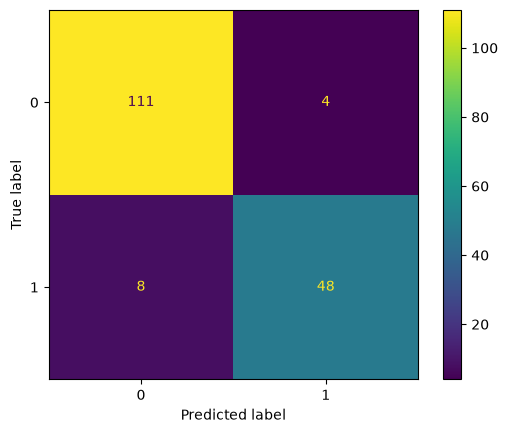

In [37]:
disp=ConfusionMatrixDisplay(cm,display_labels=model.classes_)
disp.plot()

In [38]:
import matplotlib.pyplot as plt

Threshold: 0.3
[[110   5]
 [  4  52]]


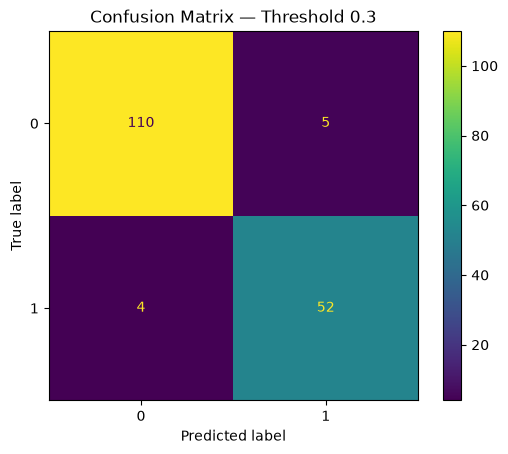

Threshold: 0.5
[[111   4]
 [  8  48]]


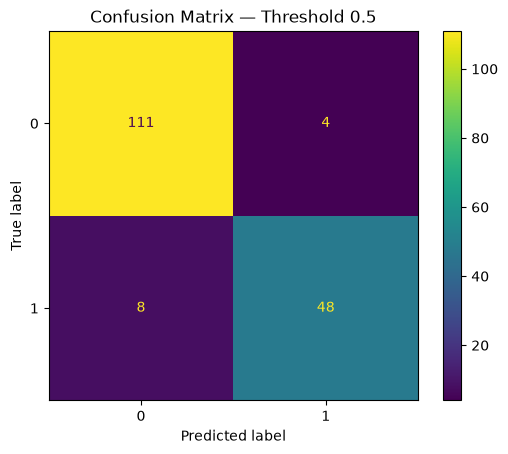

Threshold: 0.7
[[114   1]
 [  9  47]]


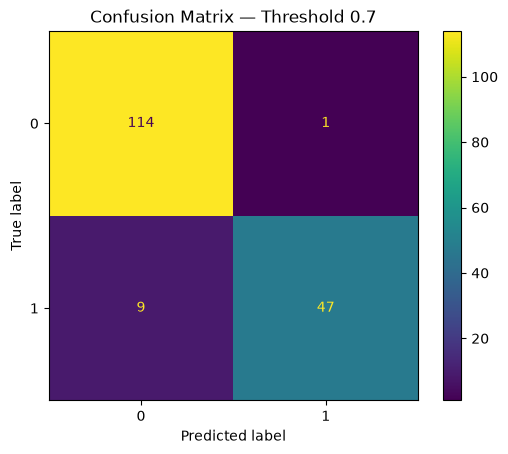

In [39]:
probability = model.predict_proba(xtest)[:, 1]

for threshold in [0.3, 0.5, 0.7]:
    ypred_threshold = (probability >= threshold).astype(int)
    cm = confusion_matrix(ytest, ypred_threshold)

    print(f"Threshold: {threshold}")
    print(cm)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=model.classes_
    ).plot()

    plt.title(f"Confusion Matrix — Threshold {threshold}")
    plt.show()

In [42]:
precision=precision_score(ytest,ypred_threshold)
print(precision)

0.9791666666666666


Threshold: 0.3
Precision: 0.912
Recall:    0.929
F1-score:  0.920

Threshold: 0.5
Precision: 0.923
Recall:    0.857
F1-score:  0.889

Threshold: 0.7
Precision: 0.979
Recall:    0.839
F1-score:  0.904



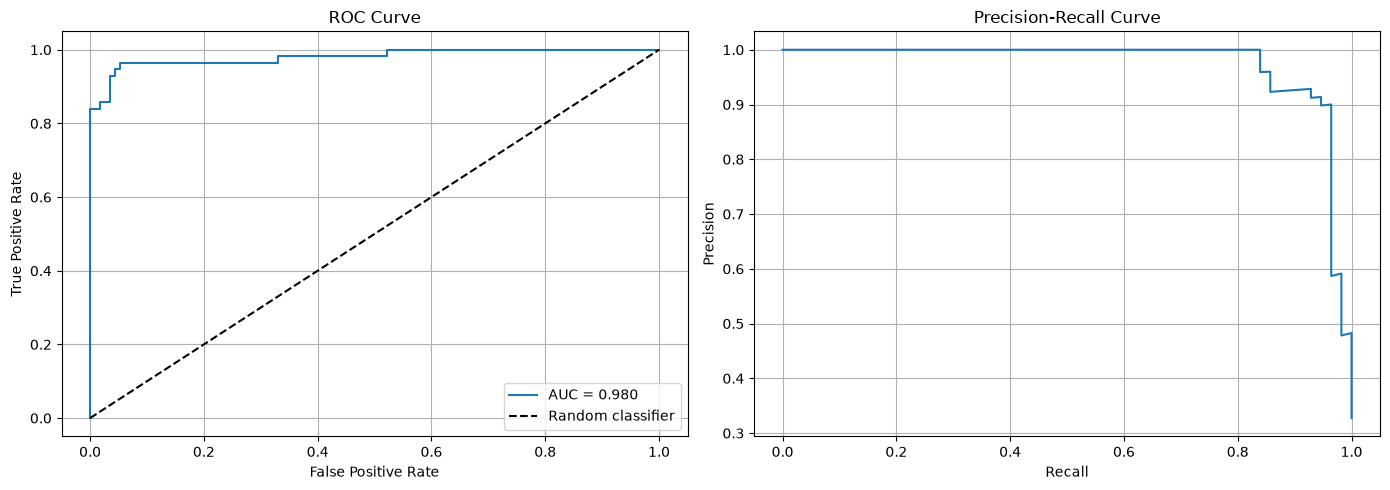

In [40]:
probability = model.predict_proba(xtest)[:, 1]

# Metrics at each classification threshold
for threshold in [0.3, 0.5, 0.7]:
    ypred_threshold = (probability >= threshold).astype(int)

    precision = precision_score(ytest, ypred_threshold, zero_division=0)
    recall = recall_score(ytest, ypred_threshold, zero_division=0)
    f1 = f1_score(ytest, ypred_threshold, zero_division=0)

    print(f"Threshold: {threshold}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall:    {recall:.3f}")
    print(f"F1-score:  {f1:.3f}")
    print()

# ROC curve and AUC
fpr, tpr, roc_thresholds = roc_curve(ytest, probability)
roc_auc = roc_auc_score(ytest, probability)

# Precision-Recall curve
precision_values, recall_values, pr_thresholds = precision_recall_curve(
    ytest,
    probability
)

# Plot both curves side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], "k--", label="Random classifier")
axes[0].set_title("ROC Curve")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(recall_values, precision_values)
axes[1].set_title("Precision-Recall Curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].grid(True)

plt.tight_layout()
plt.show()